# Notebook 13 — Report-Guided Weak Supervision (Gold-Only MRI Embedding Scope)

**Project:** Report-Guided Weak Supervision for Multi-Label Knee MRI Abnormality Detection

## Purpose
Compare the same hierarchical DINOv2 + gated slice-attention + gated series-attention MRI student under three supervision settings, using the **58 gold-labelled studies already embedded by Notebook 09**:

1. **Gold-only:** train with expert labels only.
2. **Gold + unweighted report supervision:** expert-label loss plus an auxiliary loss from valid report-derived binary labels, weighted equally.
3. **Gold + confidence-weighted report supervision:** expert-label loss plus an auxiliary report-label loss weighted by the teacher confidence.

**Scope limitation:** Notebook 09 currently contains embeddings for only the 58 gold-labelled studies. This notebook therefore does not use the 4,349 report-only studies as MRI training examples. Report-derived labels are used only for the same 58 gold studies, and only for the outer-training portion of each fold. The held-out fold's reports are excluded from training. This is a controlled auxiliary-supervision experiment, not an all-study pseudo-labelled training experiment.

**Important:** Notebook 06's `Present` / `Absent` statuses are treated as usable binary weak labels. `Uncertain` and `Not Mentioned` are masked out, even if a numeric value appears in the `_weak` column. Confidence is a loss weight, not a calibrated probability of correctness.

Keep the original Notebook 09 and Notebook 12 outputs unchanged. This notebook reuses the existing embeddings and original five-fold assignments.

## 1. Configuration and imports

Inputs:
- RSNA competition dataset (`train.csv`)
- Notebook 09 gold-scope DINOv2 output (`.npy`, metadata CSV, optional manifest)
- Notebook 06 `report_weak_labels_clean.csv`


In [1]:
import os, gc, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, hamming_loss
)
warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 5
EMBED_DIM = 384
NUM_CLASSES = 12
ATTENTION_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
EPOCHS = 40
PATIENCE = 8
MAX_GRAD_NORM = 1.0
BATCH_STUDIES = 8
THRESHOLD = 0.50
WEAK_LOSS_WEIGHT = 1.0
CONFIDENCE_FLOOR = 0.05
CONFIDENCE_POWER = 1.0

LABEL_COLS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]
OUTPUT_DIR = Path("/kaggle/working/13_weak_supervision")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
print("Device:", DEVICE)
print("Output:", OUTPUT_DIR)

Device: cpu
Output: /kaggle/working/13_weak_supervision


## 2. Locate the required input artifacts
The teacher-file override is available if Kaggle finds more than one matching CSV.

In [2]:
def find_files(filename, roots=("/kaggle/input",)):
    found = []
    for root in roots:
        if os.path.exists(root):
            for current, dirs, files in os.walk(root):
                dirs[:] = [d for d in dirs if d not in {
                    "train_images", "test_images", "train_series", "test_series",
                    "processed_data", ".git", "__pycache__", ".ipynb_checkpoints"
                }]
                if filename in files:
                    found.append(os.path.join(current, filename))
    return sorted(set(found), key=lambda p: (len(p), p))

def choose_file(filename, preferred=(), required=True):
    hits = find_files(filename)
    if not hits:
        if required:
            raise FileNotFoundError(f"Cannot find {filename}. Attach the required Kaggle input.")
        return None
    for token in preferred:
        subset = [p for p in hits if token.lower() in p.lower()]
        if subset:
            hits = subset
            break
    if len(hits) > 1:
        print(f"Multiple {filename} files found; selected {hits[0]}")
    return hits[0]

TRAIN_CSV_PATH = choose_file("train.csv", ("rsna-knee-abnormality-detection", "rsna"))
EMBEDDING_PATH = choose_file("dinov2_vits14_embeddings_float16.npy", ("09-dinov2", "dinov2"))
METADATA_PATH = choose_file("dinov2_vits14_embedding_metadata.csv", ("09-dinov2", "dinov2"))
MANIFEST_PATH = choose_file("dinov2_vits14_embedding_manifest.json", ("09-dinov2", "dinov2"), required=False)

TEACHER_FILE_OVERRIDE = None  # Set to exact /kaggle/input/... path if auto-detection picks the wrong file.
if TEACHER_FILE_OVERRIDE:
    TEACHER_PATH = TEACHER_FILE_OVERRIDE
    if not os.path.isfile(TEACHER_PATH):
        raise FileNotFoundError(TEACHER_PATH)
else:
    TEACHER_PATH = choose_file("report_weak_labels_clean.csv", ("06", "report", "teacher"))

print("train.csv:", TRAIN_CSV_PATH)
print("Embeddings:", EMBEDDING_PATH)
print("Metadata:", METADATA_PATH)
print("Manifest:", MANIFEST_PATH)
print("Teacher labels:", TEACHER_PATH)

train.csv: /kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv
Embeddings: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embeddings_float16.npy
Metadata: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_metadata.csv
Manifest: /kaggle/input/notebooks/minnieg12/09-dinov2/dinov2_vits14_embedding_manifest.json
Teacher labels: /kaggle/input/notebooks/shambhavisinha254/06-llm-report-teacher/report_weak_labels_clean.csv


## 3. Load data and validate the 58-study embedding cache
This cell intentionally expects the existing gold-only Notebook 09 cache.

In [3]:
train = pd.read_csv(TRAIN_CSV_PATH)
meta = pd.read_csv(METADATA_PATH)
emb_memmap = np.load(EMBEDDING_PATH, mmap_mode="r")
teacher = pd.read_csv(TEACHER_PATH)

for df in (train, meta, teacher):
    if "StudyInstanceUID" not in df.columns:
        raise ValueError("Every input table must contain StudyInstanceUID.")
    df["StudyInstanceUID"] = df["StudyInstanceUID"].astype(str)

missing_train = [c for c in ["StudyInstanceUID"] + LABEL_COLS if c not in train.columns]
missing_meta = [c for c in ["Embedding_Index", "StudyInstanceUID", "SeriesInstanceUID", "fold"] if c not in meta.columns]
missing_teacher = [c for c in ["StudyInstanceUID"] + [f"{x}_{suffix}" for x in LABEL_COLS for suffix in ("status", "weak", "confidence")] if c not in teacher.columns]
if missing_train: raise ValueError(f"train.csv missing columns: {missing_train}")
if missing_meta: raise ValueError(f"Embedding metadata missing columns: {missing_meta}")
if missing_teacher: raise ValueError(f"Notebook 06 teacher CSV missing columns: {missing_teacher}")

if emb_memmap.ndim != 2 or emb_memmap.shape[1] != EMBED_DIM:
    raise ValueError(f"Expected embeddings [N,{EMBED_DIM}], got {emb_memmap.shape}.")
if len(meta) != len(emb_memmap):
    raise ValueError("Embedding and metadata row counts differ.")
meta["Embedding_Index"] = pd.to_numeric(meta["Embedding_Index"], errors="raise").astype(int)
meta["fold"] = pd.to_numeric(meta["fold"], errors="raise").astype(int)
if meta["Embedding_Index"].duplicated().any():
    raise ValueError("Embedding_Index contains duplicates.")
meta = meta.sort_values("Embedding_Index").reset_index(drop=True)
if not np.array_equal(meta["Embedding_Index"].to_numpy(), np.arange(len(meta))):
    raise ValueError("Embedding_Index must be contiguous from 0 to N-1.")

for col in LABEL_COLS:
    train[col] = pd.to_numeric(train[col], errors="coerce")
gold = train.dropna(subset=LABEL_COLS).copy()
if gold["StudyInstanceUID"].duplicated().any():
    raise ValueError("Duplicate gold study rows in train.csv.")
gold[LABEL_COLS] = gold[LABEL_COLS].astype(np.float32)
if not gold[LABEL_COLS].isin([0, 1]).all().all():
    raise ValueError("Gold labels must be binary 0/1.")

gold_ids = set(gold["StudyInstanceUID"])
embedded_ids = set(meta["StudyInstanceUID"])
if len(gold_ids) != 58:
    raise ValueError(f"Expected 58 gold studies; found {len(gold_ids)}.")
if embedded_ids != gold_ids:
    raise ValueError(
        f"Expected gold-only embedding coverage. Missing gold={len(gold_ids-embedded_ids)}, "
        f"unexpected embedded studies={len(embedded_ids-gold_ids)}."
    )
if not np.array_equal(meta["Embedding_Index"].to_numpy(), np.arange(len(meta))):
    raise ValueError("Embedding index integrity check failed.")
if not np.isfinite(np.asarray(emb_memmap)).all():
    raise ValueError("Non-finite embedding values detected.")

if MANIFEST_PATH:
    with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
        manifest = json.load(f)
    print("Notebook 09 manifest:", manifest)
    if manifest.get("smoke_test") is True:
        raise RuntimeError("Notebook 09 cache is marked as a smoke test.")
    if manifest.get("data_scope", "gold") not in ("gold", "all_indexed"):
        raise RuntimeError("Unexpected Notebook 09 data_scope.")
embeddings = np.asarray(emb_memmap, dtype=np.float32)
del emb_memmap

print("Gold studies:", len(gold_ids))
print("Embedded studies:", len(embedded_ids))
print("Embedding rows:", len(meta))
print("Embedding shape:", embeddings.shape)
print("Original fold counts:", meta[["StudyInstanceUID", "fold"]].drop_duplicates()["fold"].value_counts().sort_index().to_dict())

Notebook 09 manifest: {'model_name': 'hf_hub:timm/vit_small_patch14_dinov2.lvd142m', 'embedding_dim': 384, 'input_size': [3, 518, 518], 'source_size': [3, 224, 224], 'data_scope': 'gold', 'smoke_test': False, 'num_studies': 58, 'num_embeddings': 10528, 'dtype': 'float16', 'seed': 42}
Gold studies: 58
Embedded studies: 58
Embedding rows: 10528
Embedding shape: (10528, 384)
Original fold counts: {0: 12, 1: 12, 2: 12, 3: 11, 4: 11}


## 4. Adapt Notebook 06 labels: use only Present / Absent

The actual Notebook 06 schema is `<finding>_status`, `<finding>_weak`, and `<finding>_confidence`. The status field determines whether a label is usable. `Uncertain` and `Not Mentioned` are masked, not treated as negatives.

In [4]:
if teacher["StudyInstanceUID"].duplicated().any():
    raise ValueError("Teacher CSV must contain at most one row per StudyInstanceUID.")

teacher = teacher.set_index("StudyInstanceUID", drop=False)
weak_targets = {}
weak_weights = {}
weak_valid = {}
status_summary = []

for label in LABEL_COLS:
    status_col = f"{label}_status"
    weak_col = f"{label}_weak"
    conf_col = f"{label}_confidence"

    status = teacher[status_col].fillna("Not Mentioned").astype(str).str.strip()
    raw_y = pd.to_numeric(teacher[weak_col], errors="coerce")
    conf = pd.to_numeric(teacher[conf_col], errors="coerce").fillna(0.0).clip(0.0, 1.0)

    valid = status.isin(["Present", "Absent"]) & raw_y.isin([0, 1])
    # Enforce semantic consistency from Notebook 06 status.
    y = raw_y.copy()
    y.loc[status == "Present"] = 1.0
    y.loc[status == "Absent"] = 0.0

    weak_targets[label] = y
    weak_weights[label] = conf
    weak_valid[label] = valid

    status_summary.append({
        "finding": label,
        "Present": int((status == "Present").sum()),
        "Absent": int((status == "Absent").sum()),
        "Uncertain": int((status == "Uncertain").sum()),
        "Not_Mentioned": int((status == "Not Mentioned").sum()),
        "Usable": int(valid.sum())
    })

status_summary_df = pd.DataFrame(status_summary)
display(status_summary_df)

,finding,Present,Absent,Uncertain,Not_Mentioned,Usable
0,ACL,798,909,4,2696,1707
1,MCL,718,943,2,2744,1661
2,Medial Meniscus,1970,230,8,2199,2200
3,Lateral Meniscus,1514,789,8,2096,2303
4,Medial OA,97,39,0,4271,136
5,Lateral OA,64,43,1,4299,107
6,PF OA,126,31,1,4249,157
7,Effusion,1792,508,1,2106,2300
8,Synovitis,305,12,1,4089,317
9,Baker's,560,476,2,3369,1036


## 5. Preserve the original five gold-study folds and build MRI bags

The fold assignments are read from the Notebook 09 embedding metadata. No new folds are generated. Each study is represented as series, and each series as its ordered DINOv2 embedding instances.

In [5]:
fold_rows = meta[["StudyInstanceUID", "fold"]].drop_duplicates()
if fold_rows["StudyInstanceUID"].duplicated().any():
    raise ValueError("A study has more than one fold assignment.")
if set(fold_rows["StudyInstanceUID"]) != gold_ids:
    raise ValueError("Fold metadata must cover exactly the 58 gold studies.")
if set(fold_rows["fold"].unique()) != set(range(N_FOLDS)):
    raise ValueError(f"Expected fold IDs 0..4; got {sorted(fold_rows['fold'].unique())}.")
fold_map = dict(zip(fold_rows["StudyInstanceUID"], fold_rows["fold"].astype(int)))
fold_counts = pd.Series(fold_map).value_counts().sort_index().to_dict()
if sorted(fold_counts.values()) != [11, 11, 12, 12, 12]:
    raise ValueError(f"Unexpected original fold sizes: {fold_counts}")
gold = gold.set_index("StudyInstanceUID").loc[sorted(gold_ids)].reset_index()
gold_lookup = gold.set_index("StudyInstanceUID")[LABEL_COLS]
study_ids = sorted(gold_ids)

meta = meta.sort_values(["StudyInstanceUID", "SeriesInstanceUID", "Embedding_Index"]).reset_index(drop=True)
study_groups = {}
for sid, sdf in meta.groupby("StudyInstanceUID", sort=True):
    series_groups = []
    for series_id, rdf in sdf.groupby("SeriesInstanceUID", sort=True):
        idx = rdf["Embedding_Index"].to_numpy(dtype=np.int64)
        if len(idx):
            series_groups.append((str(series_id), idx))
    if not series_groups:
        raise ValueError(f"No MRI series found for study {sid}.")
    study_groups[str(sid)] = series_groups

def get_study_arrays(sid):
    return [embeddings[idx] for _, idx in study_groups[str(sid)]]

print("Original fold counts:", fold_counts)
print("Studies:", len(study_groups))
print("Series:", sum(len(v) for v in study_groups.values()))
print("2.5D instances:", len(meta))

Original fold counts: {0: 12, 1: 12, 2: 12, 3: 11, 4: 11}
Studies: 58
Series: 336
2.5D instances: 10528


## 6. Build the hierarchical DINOv2 + gated-attention student
This matches the study-level architecture used in Notebook 12.

In [6]:
class GatedAttentionPool(nn.Module):
    def __init__(self, input_dim=EMBED_DIM, attention_dim=ATTENTION_DIM):
        super().__init__()
        self.norm = nn.LayerNorm(input_dim)
        self.v = nn.Linear(input_dim, attention_dim)
        self.u = nn.Linear(input_dim, attention_dim)
        self.w = nn.Linear(attention_dim, 1, bias=False)

    def forward(self, instances):
        x = self.norm(instances)
        scores = self.w(torch.tanh(self.v(x)) * torch.sigmoid(self.u(x))).squeeze(-1)
        weights = torch.softmax(scores, dim=0)
        pooled = torch.sum(weights.unsqueeze(-1) * x, dim=0)
        return pooled, weights

class HierarchicalDINOv2MIL(nn.Module):
    def __init__(self):
        super().__init__()
        self.slice_attention = GatedAttentionPool()
        self.series_attention = GatedAttentionPool()
        self.classifier = nn.Sequential(
            nn.LayerNorm(EMBED_DIM),
            nn.Linear(EMBED_DIM, HIDDEN_DIM),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN_DIM, NUM_CLASSES)
        )

    def forward_study(self, series_arrays):
        series_vectors = []
        for arr in series_arrays:
            x = torch.as_tensor(arr, dtype=torch.float32, device=DEVICE)
            pooled, _ = self.slice_attention(x)
            series_vectors.append(pooled)
        study_vector, _ = self.series_attention(torch.stack(series_vectors, dim=0))
        return self.classifier(study_vector)

def make_model():
    return HierarchicalDINOv2MIL().to(DEVICE)

sample_model = make_model()
with torch.no_grad():
    sample_logits = sample_model.forward_study(get_study_arrays(study_ids[0]))
assert sample_logits.shape == (NUM_CLASSES,)
assert torch.isfinite(sample_logits).all()
print(sample_model)
print("Trainable parameters:", sum(p.numel() for p in sample_model.parameters() if p.requires_grad))
del sample_model, sample_logits
gc.collect()

HierarchicalDINOv2MIL(
  (slice_attention): GatedAttentionPool(
    (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    (v): Linear(in_features=384, out_features=128, bias=True)
    (u): Linear(in_features=384, out_features=128, bias=True)
    (w): Linear(in_features=128, out_features=1, bias=False)
  )
  (series_attention): GatedAttentionPool(
    (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    (v): Linear(in_features=384, out_features=128, bias=True)
    (u): Linear(in_features=384, out_features=128, bias=True)
    (w): Linear(in_features=128, out_features=1, bias=False)
  )
  (classifier): Sequential(
    (0): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    (1): Linear(in_features=384, out_features=128, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=12, bias=True)
  )
)
Trainable parameters: 250508


0

## 7. Gold and report-supervision losses

For each training study, the gold loss always uses the expert labels. In the two weak-supervision modes, an additional report-derived loss is applied to the **same outer-training studies only**. The report loss is masked finding-by-finding where status is `Uncertain` or `Not Mentioned`.

In [7]:
def weak_arrays_for_study(sid):
    if sid not in teacher.index:
        return (
            np.zeros(NUM_CLASSES, dtype=np.float32),
            np.zeros(NUM_CLASSES, dtype=np.float32),
            np.zeros(NUM_CLASSES, dtype=bool)
        )
    row = teacher.loc[sid]
    ys, ws, ms = [], [], []
    for label in LABEL_COLS:
        status = str(row[f"{label}_status"]).strip() if pd.notna(row[f"{label}_status"]) else "Not Mentioned"
        y = pd.to_numeric(pd.Series([row[f"{label}_weak"]]), errors="coerce").iloc[0]
        c = pd.to_numeric(pd.Series([row[f"{label}_confidence"]]), errors="coerce").iloc[0]
        ok = status in ("Present", "Absent") and pd.notna(y) and float(y) in (0.0, 1.0)
        if status == "Present": y = 1.0
        if status == "Absent": y = 0.0
        ys.append(float(y) if ok else 0.0)
        ws.append(float(np.clip(c if pd.notna(c) else 0.0, 0.0, 1.0)))
        ms.append(bool(ok))
    return np.asarray(ys, np.float32), np.asarray(ws, np.float32), np.asarray(ms, bool)

def weighted_weak_bce(logits, targets, weights, mask):
    per_label = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    effective = weights * mask.float()
    denom = effective.sum()
    if denom.item() <= 0:
        return None
    return (per_label * effective).sum() / denom

def study_loss(model, sid, mode):
    arrays = get_study_arrays(sid)
    logits = model.forward_study(arrays)
    gold_y = torch.as_tensor(gold_lookup.loc[sid].to_numpy(dtype=np.float32), device=DEVICE)
    gold_loss = F.binary_cross_entropy_with_logits(logits, gold_y)

    if mode == "gold_only":
        return gold_loss
    weak_y, weak_c, weak_m = weak_arrays_for_study(sid)
    wy = torch.as_tensor(weak_y, device=DEVICE)
    if mode == "confidence_weighted":
        effective_weights = weak_c
    else:
        effective_weights = weak_m.astype(np.float32)
    wc = torch.as_tensor(effective_weights, device=DEVICE)
    wm = torch.as_tensor(weak_m, device=DEVICE)
    weak_loss = weighted_weak_bce(logits, wy, wc, wm)
    if weak_loss is None:
        return gold_loss
    return gold_loss + WEAK_LOSS_WEIGHT * weak_loss

def train_epoch(model, ids, mode, optimizer, fold, epoch, stage_offset=0):
    model.train()
    rng = np.random.RandomState(SEED + fold * 10000 + epoch + stage_offset)
    order = list(rng.permutation(np.asarray(ids, dtype=object)))
    losses = []
    # One study per optimizer step avoids padding variable-size MRI bags.
    for sid in order:
        optimizer.zero_grad(set_to_none=True)
        loss = study_loss(model, str(sid), mode)
        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss in fold {fold}, study {sid}.")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses))

@torch.no_grad()
def evaluate_loss(model, ids):
    model.eval()
    losses = []
    for sid in ids:
        logits = model.forward_study(get_study_arrays(sid))
        y = torch.as_tensor(gold_lookup.loc[sid].to_numpy(dtype=np.float32), device=DEVICE)
        losses.append(float(F.binary_cross_entropy_with_logits(logits, y).cpu()))
    return float(np.mean(losses))

@torch.no_grad()
def predict_ids(model, ids):
    model.eval()
    probs = []
    for sid in ids:
        logits = model.forward_study(get_study_arrays(sid))
        probs.append(torch.sigmoid(logits).cpu().numpy())
    return np.vstack(probs)

## 8. Metrics and leakage-safe five-fold training

For each fold:
- The outer held-out gold fold is never used for training or epoch selection.
- Inner validation is drawn only from the outer-training gold studies and uses expert labels.
- The final fold model is reinitialized and refit on the complete outer-training gold set.
- Report-derived auxiliary labels are applied only to those same outer-training studies.
- The held-out fold is evaluated once using expert labels.

In [8]:
def calculate_metrics(y_true, y_prob):
    y_pred = (y_prob >= THRESHOLD).astype(int)
    aucs, aps = [], []
    for j in range(y_true.shape[1]):
        if len(np.unique(y_true[:, j])) > 1:
            aucs.append(roc_auc_score(y_true[:, j], y_prob[:, j]))
            aps.append(average_precision_score(y_true[:, j], y_prob[:, j]))
    return {
        "macro_roc_auc": float(np.mean(aucs)) if aucs else np.nan,
        "macro_pr_auc": float(np.mean(aps)) if aps else np.nan,
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "hamming_loss": float(hamming_loss(y_true, y_pred))
    }

def run_one_fold(fold, mode):
    outer_train = sorted(s for s in study_ids if fold_map[s] != fold)
    outer_val = sorted(s for s in study_ids if fold_map[s] == fold)
    rng = np.random.RandomState(SEED + 1000 + fold)
    shuffled = list(rng.permutation(np.asarray(outer_train, dtype=object)))
    n_inner_val = max(1, int(round(0.20 * len(shuffled))))
    inner_val = sorted(map(str, shuffled[:n_inner_val]))
    inner_train = sorted(map(str, shuffled[n_inner_val:]))

    seed_everything(SEED + fold)
    selection_model = make_model()
    optimizer = torch.optim.AdamW(selection_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    best_loss, best_epoch, patience_count = np.inf, 0, 0
    history = []

    print(f"Mode={mode} | fold={fold} | outer train={len(outer_train)} | held-out={len(outer_val)}")
    for epoch in range(1, EPOCHS + 1):
        tr_loss = train_epoch(selection_model, inner_train, mode, optimizer, fold, epoch)
        va_loss = evaluate_loss(selection_model, inner_val)
        history.append({"mode": mode, "fold": fold, "epoch": epoch,
                        "train_loss": tr_loss, "inner_val_loss": va_loss})
        print(f"  epoch {epoch:02d}: train={tr_loss:.4f}, inner-val={va_loss:.4f}")
        if va_loss < best_loss - 1e-6:
            best_loss, best_epoch, patience_count = va_loss, epoch, 0
        else:
            patience_count += 1
        if patience_count >= PATIENCE:
            print("  Early stopping.")
            break

    del selection_model, optimizer
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    if best_epoch == 0:
        raise RuntimeError(f"No best epoch selected for mode={mode}, fold={fold}.")

    seed_everything(SEED + 10000 + fold)
    final_model = make_model()
    final_optimizer = torch.optim.AdamW(final_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    for epoch in range(1, best_epoch + 1):
        loss = train_epoch(final_model, outer_train, mode, final_optimizer, fold, epoch, stage_offset=50000)
        print(f"  refit epoch {epoch:02d}/{best_epoch}: loss={loss:.4f}")

    y_prob = predict_ids(final_model, outer_val)
    y_true = gold_lookup.loc[outer_val, LABEL_COLS].to_numpy(dtype=np.int32)
    metrics = calculate_metrics(y_true, y_prob)
    checkpoint = OUTPUT_DIR / f"{mode}_fold_{fold}.pth"
    torch.save({
        "mode": mode, "fold": int(fold), "model_state_dict": final_model.state_dict(),
        "label_cols": LABEL_COLS, "embedding_dim": EMBED_DIM,
        "architecture": "DINOv2 -> gated slice attention per series -> gated series attention per study",
        "best_epoch": int(best_epoch), "outer_train_studies": outer_train,
        "outer_heldout_studies": outer_val, "threshold": THRESHOLD
    }, checkpoint)
    del final_model, final_optimizer
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    pred_rows = []
    for i, sid in enumerate(outer_val):
        row = {"StudyInstanceUID": sid, "fold": int(fold), "mode": mode}
        for j, label in enumerate(LABEL_COLS):
            row[f"{label}_true"] = int(y_true[i, j])
            row[f"{label}_prob"] = float(y_prob[i, j])
        pred_rows.append(row)
    metrics.update({"mode": mode, "fold": int(fold), "best_epoch": int(best_epoch),
                    "n_outer_train": len(outer_train), "n_outer_heldout": len(outer_val),
                    "inner_best_val_loss": float(best_loss)})
    return metrics, pd.DataFrame(pred_rows), history, checkpoint

MODES = ["gold_only", "gold_plus_unweighted_weak", "gold_plus_confidence_weighted_weak"]
metrics_rows, prediction_frames, history_rows = [], [], []
checkpoint_paths = []

for mode in MODES:
    print("\n" + "=" * 78 + "\n", mode, "\n" + "=" * 78)
    for fold in range(N_FOLDS):
        metrics, pred_df, history, checkpoint = run_one_fold(fold, mode)
        metrics_rows.append(metrics)
        prediction_frames.append(pred_df)
        history_rows.extend(history)
        checkpoint_paths.append(str(checkpoint))

metrics_df = pd.DataFrame(metrics_rows)
predictions_df = pd.concat(prediction_frames, ignore_index=True)
history_df = pd.DataFrame(history_rows)

metrics_df.to_csv(OUTPUT_DIR / "fold_metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_DIR / "oof_predictions_all_modes.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
display(metrics_df)


 gold_only 
Mode=gold_only | fold=0 | outer train=46 | held-out=12
  epoch 01: train=0.6424, inner-val=0.8236
  epoch 02: train=0.6328, inner-val=0.7345
  epoch 03: train=0.6021, inner-val=0.8896
  epoch 04: train=0.6104, inner-val=0.7815
  epoch 05: train=0.5636, inner-val=0.7696
  epoch 06: train=0.5444, inner-val=0.7757
  epoch 07: train=0.4804, inner-val=0.7788
  epoch 08: train=0.4451, inner-val=0.8732
  epoch 09: train=0.4221, inner-val=0.7624
  epoch 10: train=0.3903, inner-val=0.9272
  Early stopping.
  refit epoch 01/2: loss=0.6682
  refit epoch 02/2: loss=0.6421
Mode=gold_only | fold=1 | outer train=46 | held-out=12
  epoch 01: train=0.6705, inner-val=0.6192
  epoch 02: train=0.6411, inner-val=0.6373
  epoch 03: train=0.6289, inner-val=0.6207
  epoch 04: train=0.6192, inner-val=0.6443
  epoch 05: train=0.6084, inner-val=0.6191
  epoch 06: train=0.5934, inner-val=0.6303
  epoch 07: train=0.5667, inner-val=0.6443
  epoch 08: train=0.5436, inner-val=0.6166
  epoch 09: train=0.5

,macro_roc_auc,macro_pr_auc,macro_f1,macro_precision,macro_recall,hamming_loss,mode,fold,best_epoch,n_outer_train,n_outer_heldout,inner_best_val_loss
0,0.510999,0.504145,0.033333,0.083333,0.020833,0.270833,gold_only,0,2,46,12,0.734525
1,0.523677,0.533189,0.385828,0.519742,0.356944,0.333333,gold_only,1,8,46,12,0.616576
2,0.550353,0.543111,0.078070,0.069444,0.097222,0.347222,gold_only,2,1,46,12,0.635603
3,0.551058,0.477659,0.134716,0.125000,0.183333,0.356061,gold_only,3,3,47,11,0.536925
4,0.522652,0.511370,0.219727,0.267130,0.209325,0.386364,gold_only,4,11,47,11,0.556997
5,0.536131,0.451400,0.273878,0.222117,0.430556,0.451389,gold_plus_unweighted_weak,0,8,46,12,0.718026
6,0.539583,0.540864,0.327362,0.240741,0.527778,0.437500,gold_plus_unweighted_weak,1,3,46,12,0.671377
7,0.652050,0.626031,0.509393,0.571976,0.546429,0.347222,gold_plus_unweighted_weak,2,8,46,12,0.629082
8,0.658664,0.546985,0.307925,0.238636,0.458333,0.378788,gold_plus_unweighted_weak,3,3,47,11,0.645223
9,0.540443,0.520694,0.224137,0.185038,0.326389,0.454545,gold_plus_unweighted_weak,4,8,47,11,0.619045


## 9. Per-finding results and report-label coverage diagnostics

In [9]:
per_finding_rows = []
for mode in MODES:
    part = predictions_df[predictions_df["mode"] == mode].set_index("StudyInstanceUID")
    ids = sorted(gold_ids)
    y_true = gold_lookup.loc[ids, LABEL_COLS].to_numpy(dtype=int)
    y_prob = part.loc[ids, [f"{c}_prob" for c in LABEL_COLS]].to_numpy(dtype=float)
    for j, label in enumerate(LABEL_COLS):
        yp = (y_prob[:, j] >= THRESHOLD).astype(int)
        per_finding_rows.append({
            "mode": mode, "finding": label,
            "precision": precision_score(y_true[:, j], yp, zero_division=0),
            "recall": recall_score(y_true[:, j], yp, zero_division=0),
            "f1": f1_score(y_true[:, j], yp, zero_division=0),
            "roc_auc": roc_auc_score(y_true[:, j], y_prob[:, j]) if len(np.unique(y_true[:, j])) > 1 else np.nan,
            "pr_auc": average_precision_score(y_true[:, j], y_prob[:, j]) if len(np.unique(y_true[:, j])) > 1 else np.nan
        })
per_finding_df = pd.DataFrame(per_finding_rows)
per_finding_df.to_csv(OUTPUT_DIR / "per_finding_comparison.csv", index=False)

# Coverage for the teacher labels specifically on the 58 gold studies.
coverage_rows = []
for label in LABEL_COLS:
    status = teacher[f"{label}_status"].fillna("Not Mentioned").astype(str).str.strip()
    valid = status.isin(["Present", "Absent"])
    coverage_rows.append({
        "finding": label,
        "gold_studies_with_teacher_row": int(len(set(teacher.index) & gold_ids)),
        "present": int((status == "Present").sum()),
        "absent": int((status == "Absent").sum()),
        "uncertain": int((status == "Uncertain").sum()),
        "not_mentioned": int((status == "Not Mentioned").sum()),
        "usable_binary_labels": int(valid.sum())
    })
teacher_coverage_df = pd.DataFrame(coverage_rows)
teacher_coverage_df.to_csv(OUTPUT_DIR / "teacher_label_coverage.csv", index=False)
display(per_finding_df.head(12))
display(teacher_coverage_df)

,mode,finding,precision,recall,f1,roc_auc,pr_auc
0,gold_only,ACL,0.400000,0.166667,0.235294,0.399510,0.369693
1,gold_only,MCL,0.000000,0.000000,0.000000,0.408163,0.172804
2,gold_only,Medial Meniscus,0.428571,0.230769,0.300000,0.486779,0.448007
3,gold_only,Lateral Meniscus,1.000000,0.130435,0.230769,0.591304,0.519083
4,gold_only,Medial OA,1.000000,0.133333,0.235294,0.627907,0.442339
5,gold_only,Lateral OA,0.500000,0.090909,0.153846,0.328820,0.227322
6,gold_only,PF OA,0.625000,0.238095,0.344828,0.576577,0.510123
7,gold_only,Effusion,0.571429,0.685714,0.623377,0.532919,0.673292
8,gold_only,Synovitis,0.440000,0.407407,0.423077,0.488650,0.511446
9,gold_only,Baker's,0.000000,0.000000,0.000000,0.422101,0.186684


,finding,gold_studies_with_teacher_row,present,absent,uncertain,not_mentioned,usable_binary_labels
0,ACL,58,798,909,4,2696,1707
1,MCL,58,718,943,2,2744,1661
2,Medial Meniscus,58,1970,230,8,2199,2200
3,Lateral Meniscus,58,1514,789,8,2096,2303
4,Medial OA,58,97,39,0,4271,136
5,Lateral OA,58,64,43,1,4299,107
6,PF OA,58,126,31,1,4249,157
7,Effusion,58,1792,508,1,2106,2300
8,Synovitis,58,305,12,1,4089,317
9,Baker's,58,560,476,2,3369,1036


## 10. Aggregate comparison plots and summary tables

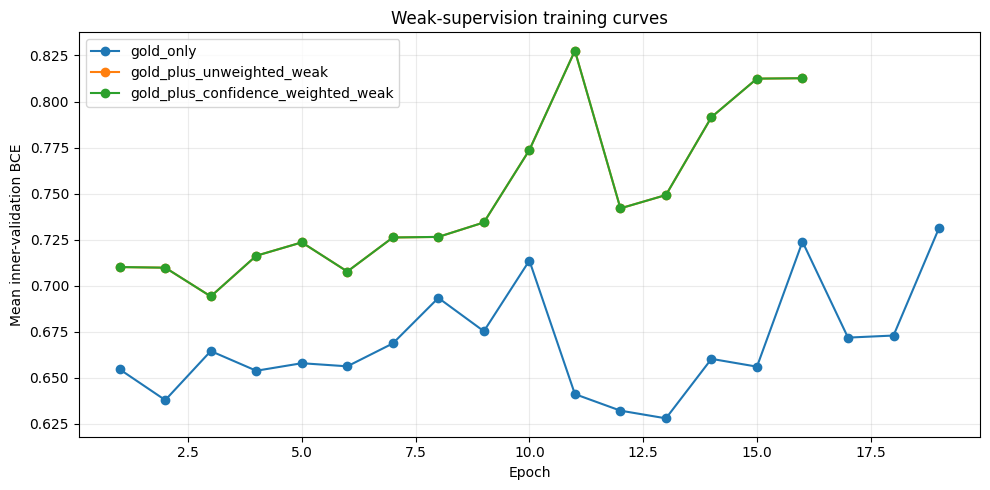

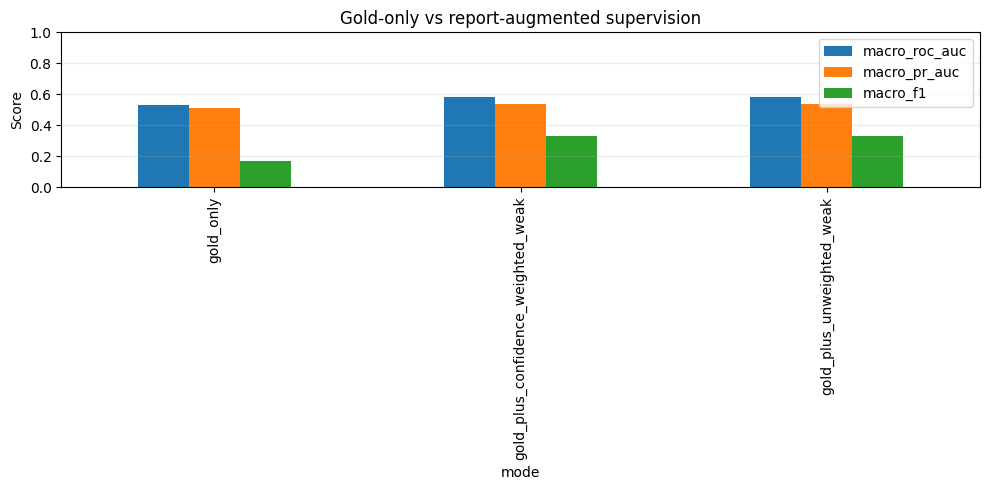

,mode,macro_roc_auc,macro_pr_auc,macro_f1,macro_precision,macro_recall,hamming_loss,fold,best_epoch,n_outer_train,n_outer_heldout,inner_best_val_loss
0,gold_only,0.531748,0.513895,0.170335,0.212930,0.173532,0.338763,2.0,5.0,46.4,11.6,0.616125
1,gold_plus_confidence_weighted_weak,0.585374,0.537195,0.328539,0.291702,0.457897,0.413889,2.0,6.0,46.4,11.6,0.656551
2,gold_plus_unweighted_weak,0.585374,0.537195,0.328539,0.291702,0.457897,0.413889,2.0,6.0,46.4,11.6,0.656551


In [10]:
summary = metrics_df.groupby("mode").agg(["mean", "std"])
summary.to_csv(OUTPUT_DIR / "supervision_comparison_summary.csv")
comparison = metrics_df.groupby("mode").mean(numeric_only=True).reset_index()
comparison.to_csv(OUTPUT_DIR / "hierarchical_dinov2_supervision_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
for mode in MODES:
    h = history_df[history_df["mode"] == mode]
    curve = h.groupby("epoch")["inner_val_loss"].mean()
    ax.plot(curve.index, curve.values, marker="o", label=mode)
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean inner-validation BCE")
ax.set_title("Weak-supervision training curves")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "supervision_learning_curves.png", dpi=160)
plt.show()

metric_cols = ["macro_roc_auc", "macro_pr_auc", "macro_f1"]
fig, ax = plt.subplots(figsize=(10, 5))
comparison.set_index("mode")[metric_cols].plot(kind="bar", ax=ax)
ax.set_ylabel("Score")
ax.set_title("Gold-only vs report-augmented supervision")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "supervision_comparison.png", dpi=160)
plt.show()
display(comparison)

## 11. Final integrity checks and artifact audit

In [11]:
# Every gold study must be evaluated exactly once in each mode.
for mode in MODES:
    part = predictions_df[predictions_df["mode"] == mode]
    counts = part["StudyInstanceUID"].value_counts()
    assert set(counts.index) == gold_ids, f"OOF study coverage mismatch for {mode}"
    assert (counts == 1).all(), f"Duplicate OOF prediction in {mode}"
    assert part["fold"].map(lambda f: int(f) in range(N_FOLDS)).all()

# No report labels from held-out studies enter their fold's training set:
# the training routine selects only outer_train IDs, while the held-out IDs are disjoint.
for fold in range(N_FOLDS):
    outer_train = {s for s in study_ids if fold_map[s] != fold}
    outer_val = {s for s in study_ids if fold_map[s] == fold}
    assert outer_train.isdisjoint(outer_val)
    assert outer_train | outer_val == gold_ids

expected = [
    "fold_metrics.csv", "oof_predictions_all_modes.csv", "training_history.csv",
    "per_finding_comparison.csv", "teacher_label_coverage.csv",
    "supervision_comparison_summary.csv",
    "hierarchical_dinov2_supervision_comparison.csv",
    "supervision_learning_curves.png", "supervision_comparison.png"
]
expected += [f"{mode}_fold_{fold}.pth" for mode in MODES for fold in range(N_FOLDS)]
missing = [name for name in expected if not (OUTPUT_DIR / name).exists()]
run_summary = {
    "notebook": "13_weak_supervision.ipynb",
    "status": "completed" if not missing else "incomplete",
    "scope": "58 gold studies with existing Notebook 09 embeddings",
    "gold_studies": len(gold_ids),
    "embedded_studies": len(embedded_ids),
    "embedding_shape": list(embeddings.shape),
    "fold_counts": fold_counts,
    "modes": MODES,
    "weak_label_statuses_used": ["Present", "Absent"],
    "weak_label_statuses_masked": ["Uncertain", "Not Mentioned"],
    "weak_loss_weight": WEAK_LOSS_WEIGHT,
    "confidence_floor": CONFIDENCE_FLOOR,
    "confidence_power": CONFIDENCE_POWER,
    "device": str(DEVICE),
    "missing_artifacts": missing
}
with open(OUTPUT_DIR / "run_summary.json", "w") as f:
    json.dump(run_summary, f, indent=2)
print(json.dumps(run_summary, indent=2))
if missing:
    raise RuntimeError(f"Missing expected artifacts: {missing}")
print("\nNOTEBOOK 13 COMPLETED SUCCESSFULLY.")

{
  "notebook": "13_weak_supervision.ipynb",
  "status": "completed",
  "scope": "58 gold studies with existing Notebook 09 embeddings",
  "gold_studies": 58,
  "embedded_studies": 58,
  "embedding_shape": [
    10528,
    384
  ],
  "fold_counts": {
    "0": 12,
    "1": 12,
    "2": 12,
    "3": 11,
    "4": 11
  },
  "modes": [
    "gold_only",
    "gold_plus_unweighted_weak",
    "gold_plus_confidence_weighted_weak"
  ],
  "weak_label_statuses_used": [
    "Present",
    "Absent"
  ],
  "weak_label_statuses_masked": [
    "Uncertain",
    "Not Mentioned"
  ],
  "weak_loss_weight": 1.0,
  "confidence_floor": 0.05,
  "confidence_power": 1.0,
  "device": "cpu",
  "missing_artifacts": []
}

NOTEBOOK 13 COMPLETED SUCCESSFULLY.


## 12. Interpretation and hand-off

### Required comparisons
- `gold_only`: expert-label baseline.
- `gold_plus_unweighted_weak`: expert-label loss plus equally weighted valid report-derived binary labels.
- `gold_plus_confidence_weighted_weak`: expert-label loss plus confidence-weighted report-derived binary labels.

### Interpretation cautions
- Report labels for held-out gold studies are excluded from that fold's training.
- `Uncertain` and `Not Mentioned` are not negatives; they are masked.
- Confidence is used as a relative loss weight. It is not assumed to be a calibrated probability of correctness.
- This run uses the 58 studies with available embeddings. It does **not** train on the 4,349 report-only studies because those studies have no DINOv2 embeddings in the current cache.
- Do not claim that adding report-only MRI studies improves performance. Report the restricted scope clearly.
- Do not claim confidence weighting improves performance unless the outer-fold results support it.
- Notebook 17 inference remains MRI-only; report text is not required at inference.